In [7]:
import pandas as pd
import numpy as np
import requests
import time
import datetime
import yfinance as yf

from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import xgboost as xgb
import shap
import matplotlib.pyplot as plt

In [4]:
!pip install pandas_ta_classic
!pip install pytrends
!pip install yfinance
!pip install xgboost
!pip install shap
!pip install pandas_datareader

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 261.2/261.2 kB 6.1 MB/s eta 0:00:00


In [5]:
pip install requests

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
# load from csv for later use
data_1 = pd.read_csv('/crypto_full_2020_daily_data.csv')
data_2 = pd.read_csv('/crypto_full_2021_daily_data.csv')
data_3 = pd.read_csv('/crypto_full_2022_daily_data.csv')
data_4 = pd.read_csv('/crypto_full_2023_daily_data.csv')
data_5 = pd.read_csv('/crypto_full_2024_daily_data.csv')
data_6 = pd.read_csv('/crypto_full_2025_daily_data.csv')

FileNotFoundError: [Errno 2] No such file or directory: '/crypto_full_2020_daily_data.csv'

In [ ]:
# combine all data into one DataFrame
all_data = pd.concat([data_1, data_2, data_3, data_4, data_5, data_6], ignore_index=True)
all_data

,id,slug,name,symbol,timestamp,ref_cur_id,ref_cur_name,time_open,time_close,time_high,time_low,open,high,low,close,volume,market_cap,year
0,1,bitcoin,Bitcoin,BTC,2020-01-01 23:59:59,2781,USD,2020-01-01,2020-01-01 23:59:59,2020-01-01 15:42:01,2020-01-01 01:06:01,7.194892e+03,7.254331e+03,7.174944e+03,7.200174e+03,1.856566e+10,1.305808e+11,2020
1,1,bitcoin,Bitcoin,BTC,2020-01-02 23:59:59,2781,USD,2020-01-02,2020-01-02 23:59:59,2020-01-02 01:30:00,2020-01-02 23:02:01,7.202551e+03,7.212155e+03,6.935270e+03,6.985470e+03,2.080208e+10,1.266994e+11,2020
2,1,bitcoin,Bitcoin,BTC,2020-01-03 23:59:59,2781,USD,2020-01-03,2020-01-03 23:59:59,2020-01-03 17:04:00,2020-01-03 02:10:01,6.984429e+03,7.413715e+03,6.914996e+03,7.344884e+03,2.811148e+10,1.332334e+11,2020
3,1,bitcoin,Bitcoin,BTC,2020-01-04 23:59:59,2781,USD,2020-01-04,2020-01-04 23:59:59,2020-01-04 18:44:02,2020-01-04 00:39:02,7.345375e+03,7.427386e+03,7.309514e+03,7.410657e+03,1.844427e+10,1.344425e+11,2020
4,1,bitcoin,Bitcoin,BTC,2020-01-05 23:59:59,2781,USD,2020-01-05,2020-01-05 23:59:59,2020-01-05 18:57:00,2020-01-05 23:18:00,7.410452e+03,7.544497e+03,7.400536e+03,7.411317e+03,1.972507e+10,1.344695e+11,2020
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7646227,36406,colend,Colend,CLND,2025-05-03 23:59:59,2781,USD,2025-05-03,2025-05-03 23:59:59,2025-05-03 14:12:00,2025-05-03 21:56:00,6.958627e-02,7.133492e-02,6.932263e-02,6.996861e-02,1.991218e+04,0.000000e+00,2025
7646228,36406,colend,Colend,CLND,2025-05-04 23:59:59,2781,USD,2025-05-04,2025-05-04 23:59:59,2025-05-04 06:41:00,2025-05-04 03:17:00,6.996861e-02,7.317795e-02,6.895229e-02,7.021835e-02,2.264552e+04,0.000000e+00,2025
7646229,36407,gork-ai-agent,gork AI Agent,GORK,2025-05-03 23:59:59,2781,USD,2025-05-03,2025-05-03 23:59:59,2025-05-03 04:52:00,2025-05-03 20:05:00,5.410000e-12,6.790000e-12,3.170000e-12,3.450000e-12,7.872601e+05,0.000000e+00,2025
7646230,36407,gork-ai-agent,gork AI Agent,GORK,2025-05-04 23:59:59,2781,USD,2025-05-04,2025-05-04 23:59:59,2025-05-04 19:36:00,2025-05-04 01:48:00,3.450000e-12,1.251000e-11,2.310000e-12,9.020000e-12,8.699834e+05,0.000000e+00,2025


In [ ]:
# prepare crypto data by filtering for specific symbols, calculating volatility, converting timestamp to datetime, setting it as index, and filtering by minimum volume
def prepare_crypto_data(df, symbol=("BTC", "ETH", "XRP","BNB"), name=('Bitcoin','Ethereum','Ripple',"Binance"), min_volume=1_000_000):
    data = df[df["symbol"].isin(symbol)].copy()
    data = df[df["name"].isin(name)].copy()
    data["Volatility"] = (data["high"] - data["low"]) / data["open"]
    data["timestamp"] = pd.to_datetime(data["timestamp"])
    data = data.set_index("timestamp")
    data = data[data["volume"] >= min_volume].copy()
    return data

crypto_data = prepare_crypto_data(all_data, symbol=["BTC", "ETH", "XRP", "BNB"])
crypto_data

,id,slug,name,symbol,ref_cur_id,ref_cur_name,time_open,time_close,time_high,time_low,open,high,low,close,volume,market_cap,year,Volatility
timestamp,,,,,,,,,,,,,,,,,,
2020-01-01 23:59:59,1,bitcoin,Bitcoin,BTC,2781,USD,2020-01-01,2020-01-01 23:59:59,2020-01-01 15:42:01,2020-01-01 01:06:01,7194.891971,7254.330611,7174.944153,7200.174393,1.856566e+10,1.305808e+11,2020,0.011034
2020-01-02 23:59:59,1,bitcoin,Bitcoin,BTC,2781,USD,2020-01-02,2020-01-02 23:59:59,2020-01-02 01:30:00,2020-01-02 23:02:01,7202.551122,7212.155253,6935.269972,6985.470001,2.080208e+10,1.266994e+11,2020,0.038443
2020-01-03 23:59:59,1,bitcoin,Bitcoin,BTC,2781,USD,2020-01-03,2020-01-03 23:59:59,2020-01-03 17:04:00,2020-01-03 02:10:01,6984.428612,7413.715099,6914.995908,7344.884183,2.811148e+10,1.332334e+11,2020,0.071404
2020-01-04 23:59:59,1,bitcoin,Bitcoin,BTC,2781,USD,2020-01-04,2020-01-04 23:59:59,2020-01-04 18:44:02,2020-01-04 00:39:02,7345.375275,7427.385794,7309.514012,7410.656566,1.844427e+10,1.344425e+11,2020,0.016047
2020-01-05 23:59:59,1,bitcoin,Bitcoin,BTC,2781,USD,2020-01-05,2020-01-05 23:59:59,2020-01-05 18:57:00,2020-01-05 23:18:00,7410.451694,7544.496872,7400.535561,7411.317327,1.972507e+10,1.344695e+11,2020,0.019427
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-04-30 23:59:59,1027,ethereum,Ethereum,ETH,2781,USD,2025-04-30,2025-04-30 23:59:59,2025-04-30 12:04:00,2025-04-30 14:01:00,1799.209083,1816.689938,1736.142970,1793.775362,1.481043e+10,2.165954e+11,2025,0.044768
2025-05-01 23:59:59,1027,ethereum,Ethereum,ETH,2781,USD,2025-05-01,2025-05-01 23:59:59,2025-05-01 15:16:00,2025-05-01 00:05:00,1794.041006,1872.939522,1793.151149,1839.221584,1.586144e+10,2.220488e+11,2025,0.044474
2025-05-02 23:59:59,1027,ethereum,Ethereum,ETH,2781,USD,2025-05-02,2025-05-02 23:59:59,2025-05-02 16:06:00,2025-05-02 08:01:00,1839.174820,1869.530089,1814.730423,1842.707828,1.357017e+10,2.224764e+11,2025,0.029796


In [ ]:
# --- STEP 1: DATE PARSING (Process Date First) ---
# We normalize the 24/7 crypto timestamps to a date object for merging
crypto_data['date'] = pd.to_datetime(crypto_data.index).date
crypto_data['date'] = pd.to_datetime(crypto_data['date'])
crypto_data.head()

,id,slug,name,symbol,ref_cur_id,ref_cur_name,time_open,time_close,time_high,time_low,open,high,low,close,volume,market_cap,year,Volatility,date
timestamp,,,,,,,,,,,,,,,,,,,
2020-01-01 23:59:59,1,bitcoin,Bitcoin,BTC,2781,USD,2020-01-01,2020-01-01 23:59:59,2020-01-01 15:42:01,2020-01-01 01:06:01,7194.891971,7254.330611,7174.944153,7200.174393,1.856566e+10,1.305808e+11,2020,0.011034,2020-01-01
2020-01-02 23:59:59,1,bitcoin,Bitcoin,BTC,2781,USD,2020-01-02,2020-01-02 23:59:59,2020-01-02 01:30:00,2020-01-02 23:02:01,7202.551122,7212.155253,6935.269972,6985.470001,2.080208e+10,1.266994e+11,2020,0.038443,2020-01-02
2020-01-03 23:59:59,1,bitcoin,Bitcoin,BTC,2781,USD,2020-01-03,2020-01-03 23:59:59,2020-01-03 17:04:00,2020-01-03 02:10:01,6984.428612,7413.715099,6914.995908,7344.884183,2.811148e+10,1.332334e+11,2020,0.071404,2020-01-03
2020-01-04 23:59:59,1,bitcoin,Bitcoin,BTC,2781,USD,2020-01-04,2020-01-04 23:59:59,2020-01-04 18:44:02,2020-01-04 00:39:02,7345.375275,7427.385794,7309.514012,7410.656566,1.844427e+10,1.344425e+11,2020,0.016047,2020-01-04
2020-01-05 23:59:59,1,bitcoin,Bitcoin,BTC,2781,USD,2020-01-05,2020-01-05 23:59:59,2020-01-05 18:57:00,2020-01-05 23:18:00,7410.451694,7544.496872,7400.535561,7411.317327,1.972507e+10,1.344695e+11,2020,0.019427,2020-01-05


In [ ]:
#
import pandas_datareader.data as web


#---------------------------------------------------------------
# Enrichment: Macro features
#DGS10':   'treasury_yield_10y',
#'VIXCLS':  'vix',
#'M2SL':    'm2_money_supply',
#'DEXUSEU': 'usd_eur_rate'
# ---------------------------------------------------------------

# 1. Define indicators
fred_series = {
    'DGS10':   'treasury_yield_10y',
    'VIXCLS':  'vix',
    'M2SL':    'm2_money_supply',
    'DEXUSEU': 'usd_eur_rate'
}

# 2. Build the macro universe (2020-2024)
full_date_range = pd.date_range(start='2020-01-01', end='2025-05-04', freq='D')
macro_all = pd.DataFrame({'date': full_date_range})

for fred_code, col_name in fred_series.items():
    raw = web.DataReader(fred_code, 'fred', start='2020-01-01', end='2025-05-04')
    raw.index = pd.to_datetime(raw.index)
    raw.columns = [col_name]

    # Reindex and Forward Fill (Requirement 2.3)
    raw = raw.reindex(full_date_range).ffill().reset_index()
    raw.columns = ['date', col_name]

    macro_all = macro_all.merge(raw, on='date', how='left')
    print(f" {fred_code:8s} | Nulls: {macro_all[col_name].isnull().sum()}")

# ---------------------------------------------------------------
# 3. ROBUST MERGE (Prevents KeyError/Suffixes)
# ---------------------------------------------------------------
# Drop the columns if they already exist in 'combined' to avoid _x, _y suffixes
cols_to_drop = [c for c in macro_all.columns if c in combined.columns and c != 'date']
if cols_to_drop:
    crypto_data = crypto_data.drop(columns=cols_to_drop)
    print(f" Cleaned existing columns: {cols_to_drop}")

# Ensure both are datetime
crypto_data ['date']  = pd.to_datetime(crypto_data ['date'])
macro_all['date'] = pd.to_datetime(macro_all['date'])

# Final Merge
crypto_data = crypto_data .merge(macro_all, on='date', how='left')

# ---------------------------------------------------------------
# 4. YIELD CHANGE (Grouped calculation)
# ---------------------------------------------------------------
combined = crypto_data.sort_values(['symbol', 'date'])
crypto_data['yield_change'] = crypto_data.groupby('symbol')['treasury_yield_10y'].diff()

print("\n Macro features merged and yield_change created!")
display(crypto_data[['symbol', 'date', 'treasury_yield_10y', 'yield_change']].dropna().head(5))

ReadTimeout: HTTPSConnectionPool(host='fred.stlouisfed.org', port=443): Read timed out. (read timeout=30)

In [ ]:
# ---------------------------------------------------------------
# Enrichment: Technical Momentum & Volatility Indicators
# RSI (14), MACD, BB %B, Ultimate Oscillator, and EMA Crossover
# Indicators calculated per coin to prevent signal spillover.
# ---------------------------------------------------------------
import pandas_ta_classic as ta
import numpy as np # Added for crossover signal logic

# Apply per coin — CRITICAL: groupby to avoid cross-coin spillover
def add_technical_indicators(df):
    df = df.sort_values('date').copy()

    # 1. RSI (14-day): Momentum — overbought >70, oversold <30
    df['rsi_14'] = ta.rsi(df['close'], length=14)

    # 2. MACD: Trend — signal line crossover as buy/sell indicator
    macd = ta.macd(df['close'], fast=12, slow=26, signal=9)
    df['macd']        = macd['MACD_12_26_9']
    df['macd_signal'] = macd['MACDs_12_26_9']
    df['macd_hist']   = macd['MACDh_12_26_9']

    # 3. Ultimate Oscillator: Momentum Indicator across 3 timeframes (standard: 7, 14, 28)
    # CRITICAL: Ensure your dataframe has 'high' and 'low' columns for this to work!
    df['uo'] = ta.uo(df['high'], df['low'], df['close'], fast=7, medium=14, slow=28)

    # 4. EMA Crossover (Momentum Indicator) - Suggested by Shakira
    # Calculating a Fast EMA (9 periods) and Slow EMA (21 periods)
    df['ema_fast'] = ta.ema(df['close'], length=9)
    df['ema_slow'] = ta.ema(df['close'], length=21)

    # Creating a simple crossover signal:
    # 1 if Fast > Slow (Bullish trend), -1 if Fast < Slow (Bearish trend)
    df['ema_crossover_signal'] = np.where(df['ema_fast'] > df['ema_slow'], 1, -1)

    return df

combined = (
    combined
    .groupby('symbol', group_keys=False)
    .apply(add_technical_indicators)
    .reset_index(drop=True)
)

print(" Technical indicators added.")

# Expanded print statement to view the newly added columns
print(combined[['symbol', 'date', 'close', 'macd', 'uo', 'ema_crossover_signal']].head(10))

SyntaxError: invalid syntax (3274336065.py, line 1)

# Sentiment data extraction

**Extracting the Google trednds data for each coin for each day**

1. run 4 separate API requests against pytrends for individial coins (BTC, ETH, XRP, BNB)
2. each of them should have a different key word search for exmaple ["bitcoin","BTC"] for Bitcoin
3. do a union all for all 4 dataframes combining the values into one df
4. Merge/join this with the rest of the features joining on the coin symbol and the date

**Things to consider**
- missing value imputation
- How to avoid leaking
- Forward fill

In [ ]:
# get Google Trends data for multiple keywords over a long time range by stitching together daily data chunks with overlap for alignment
from pytrends.request import TrendReq
import time

def fetch_trends_daily_long_multi(
    keywords,
    start="2020-01-01",
    end="2025-12-31",
    geo="",
    hl="en-US",
    chunk_days=200,
    overlap_days=30,
    sleep=1.0,
    anchor=None,
):
    if anchor is None:
        anchor = keywords[0]

    pytrends = TrendReq(hl=hl, tz=0)
    start = pd.to_datetime(start)
    end = pd.to_datetime(end)

    step = chunk_days - overlap_days
    parts = []

    cur_start = start
    while cur_start <= end:
        cur_end = min(cur_start + pd.Timedelta(days=chunk_days - 1), end)
        timeframe = f"{cur_start:%Y-%m-%d} {cur_end:%Y-%m-%d}"

        pytrends.build_payload(kw_list=keywords, timeframe=timeframe, geo=geo)
        df = pytrends.interest_over_time()

        if df.empty:
            raise RuntimeError(f"No data returned for {timeframe}")

        df = df.drop(columns=["isPartial"], errors="ignore")
        parts.append(df)

        cur_start = cur_start + pd.Timedelta(days=step)
        time.sleep(sleep)

    stitched = parts[0].copy()

    for df in parts[1:]:
        o_start = max(df.index.min(), stitched.index.min())
        o_end   = min(df.index.max(), stitched.index.max())

        if o_start <= o_end:
            prev = stitched.loc[o_start:o_end, anchor]
            curr = df.loc[o_start:o_end, anchor]


            prev_mean = prev.replace(0, pd.NA).dropna().mean()
            curr_mean = curr.replace(0, pd.NA).dropna().mean()

            if pd.notna(prev_mean) and pd.notna(curr_mean) and curr_mean != 0:
                factor = prev_mean / curr_mean
                df[keywords] = df[keywords] * factor


        df = df.loc[df.index > stitched.index.max()]
        stitched = pd.concat([stitched, df], axis=0)


    max_all = stitched[keywords].to_numpy().max()
    if max_all and max_all > 0:
        stitched[keywords] = (stitched[keywords] / max_all * 100).round(2)

    return stitched



keywords = ['bitcoin','ethereum','ripple',"binance"]
df_daily = fetch_trends_daily_long_multi(
    keywords,
    start="2020-01-01",
    end="2025-12-31",
    geo="",
    chunk_days=200,
    overlap_days=30,
    sleep=1.0,
    anchor="bitcoin"
)

print(df_daily.head())
print(df_daily.tail())

            bitcoin  ethereum  ripple  binance
date                                          
2020-01-01     5.98      0.52    0.52     0.26
2020-01-02     6.76      0.52    0.52     0.26
2020-01-03     7.53      0.52    0.78     0.26
2020-01-04     6.76      0.52    0.52     0.26
2020-01-05     6.76      0.52    0.52     0.26
            bitcoin  ethereum  ripple  binance
date                                          
2025-12-27    13.76      1.90    1.42     2.37
2025-12-28    13.76      1.90    1.42     2.37
2025-12-29    14.71      2.37    1.42     2.37
2025-12-30    13.76      1.90    1.42     2.37
2025-12-31    13.28      1.90    1.42     2.37


In [ ]:
df_daily

,bitcoin,ethereum,litecoin
date,,,
2020-01-01,6.23,0.57,0.28
2020-01-02,6.80,0.57,0.28
2020-01-03,7.65,0.57,0.28
2020-01-04,6.80,0.57,0.28
2020-01-05,7.08,0.57,0.28
...,...,...,...
2025-12-27,14.52,1.94,0.00
2025-12-28,14.52,1.94,0.00
2025-12-29,15.49,1.94,0.00


In [ ]:

# ---------------------------------------------------------------
# PHASE 2: Feature Engineering & Target & Returns Variable Definition
# ---------------------------------------------------------------

# create target variable: whether the next day's return is greater than 2%
merged = merged.sort_values("time_open").copy()
merged["future_return"] = merged["close"].shift(-1) / merged["close"] - 1
merged["target"] = (merged["future_return"] > 0.02).astype("Int64")
merged.loc[merged["future_return"].isna(), "target"] = pd.NA
merged = merged.dropna(subset=["target", "observation_date"])
merged

,id,slug,name,symbol,ref_cur_id,ref_cur_name,time_open,time_close,time_high,time_low,...,observation_date,T10YIE,DXY_Close,DXY_High,DXY_Low,DXY_Open,fear_greed_idx,trend,future_return,target
366,2,litecoin,Litecoin,LTC,2781,USD,2020-01-01,2020-01-01 23:59:59,2020-01-01 15:43:01,2020-01-01 00:03:00,...,2020-12-31,1.99,89.940002,89.980003,89.519997,89.610001,11.076667,0.28,2.113020,1
732,1027,ethereum,Ethereum,ETH,2781,USD,2020-01-01,2020-01-01 23:59:59,2020-01-01 17:20:01,2020-01-01 00:59:00,...,2020-12-31,1.99,89.940002,89.980003,89.519997,89.610001,11.076667,0.57,-0.025931,0
733,1027,ethereum,Ethereum,ETH,2781,USD,2020-01-02,2020-01-02 23:59:59,2020-01-02 00:00:01,2020-01-02 23:02:02,...,2020-01-02,1.80,96.849998,96.870003,96.430000,96.480003,2.360000,0.57,53.826623,1
1,1,bitcoin,Bitcoin,BTC,2781,USD,2020-01-02,2020-01-02 23:59:59,2020-01-02 01:30:00,2020-01-02 23:02:01,...,2020-01-02,1.80,96.849998,96.870003,96.430000,96.480003,2.360000,6.80,-0.994299,0
367,2,litecoin,Litecoin,LTC,2781,USD,2020-01-02,2020-01-02 23:59:59,2020-01-02 01:09:00,2020-01-02 23:03:01,...,2020-01-02,1.80,96.849998,96.870003,96.430000,96.480003,2.360000,0.28,0.065102,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5727,2,litecoin,Litecoin,LTC,2781,USD,2025-05-03,2025-05-03 23:59:59,2025-05-03 00:03:00,2025-05-03 17:12:00,...,2025-05-02,2.27,100.000000,100.330002,99.400002,100.180000,4.533333,0.00,1105.373665,1
5603,1,bitcoin,Bitcoin,BTC,2781,USD,2025-05-03,2025-05-03 23:59:59,2025-05-03 00:06:00,2025-05-03 23:39:00,...,2025-05-02,2.27,100.000000,100.330002,99.400002,100.180000,4.533333,10.20,-0.980876,0
5851,1027,ethereum,Ethereum,ETH,2781,USD,2025-05-03,2025-05-03 23:59:59,2025-05-03 21:32:00,2025-05-03 17:09:00,...,2025-05-02,2.27,100.000000,100.330002,99.400002,100.180000,4.533333,1.36,-0.953636,0
5728,2,litecoin,Litecoin,LTC,2781,USD,2025-05-04,2025-05-04 23:59:59,2025-05-04 02:31:00,2025-05-04 23:51:00,...,2025-05-02,2.27,100.000000,100.330002,99.400002,100.180000,3.853333,0.00,1108.287257,1


In [ ]:
merged.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5851 entries, 366 to 5604
Data columns (total 28 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                5851 non-null   int64  
 1   slug              5851 non-null   object 
 2   name              5851 non-null   object 
 3   symbol            5851 non-null   object 
 4   ref_cur_id        5851 non-null   int64  
 5   ref_cur_name      5851 non-null   object 
 6   time_open         5851 non-null   object 
 7   time_close        5851 non-null   object 
 8   time_high         5851 non-null   object 
 9   time_low          5851 non-null   object 
 10  open              5851 non-null   float64
 11  high              5851 non-null   float64
 12  low               5851 non-null   float64
 13  close             5851 non-null   float64
 14  volume            5851 non-null   float64
 15  market_cap        5851 non-null   float64
 16  year              5851 non-null   int64  
 17

In [ ]:
print(f"   BUY signals: {merged['target'].sum()} ({merged['target'].mean()*100:.1f}%)")
print(f"   SELL signals: {(1 - merged['target']).sum()} ({(1 - merged['target'].mean())*100:.1f}%)")

   BUY signals: 2820 (48.2%)
   SELL signals: 3031 (51.8%)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------------------------------------------
# Data Governance: Correlation Audit (Pearson < 0.6 threshold)
# Use combined_final with the full FEATURES list
# removing 'bb_pct_b' due to high correlation
# ---------------------------------------------------------------
#### NEED TO CHANGE VARIABLES LIST HERE

FEATURES = [
    'returns',                            #Raw Momentum
    'rsi_14', 'macd_hist', #'bb_pct_b',    # Technical Oscillators
    'volume_zscore',                      # Raw Sentiment Proxy
    'vol_macro_interaction',              # Engineered Signal
    'treasury_yield_10y', 'yield_change', # Macro Rates
    'vix', 'm2_money_supply',             # Market Stress & Liquidity
    'usd_eur_rate'                        # Currency Strength
]

corr_matrix = combined[FEATURES].corr()

# ---- Text audit: flag pairs > 0.6 ----
high_corr = np.where(np.abs(corr_matrix) > 0.6)
high_corr_list = [
    (corr_matrix.index[x], corr_matrix.columns[y], corr_matrix.iloc[x, y])
    for x, y in zip(*high_corr) if x != y and x < y
]

if high_corr_list:
    print("⚠️  Feature pairs exceeding the 0.6 Pearson threshold:")
    for feat_a, feat_b, val in high_corr_list:
        flag = "🔴 REMOVE/REVIEW" if abs(val) > 0.85 else "🟡 MONITOR"
        print(f"  {flag}  {feat_a}  <->  {feat_b}:  r = {val:.3f}")
else:
    print("✅ No feature pairs exceed the 0.6 Pearson threshold.")

# ---- Visual: heatmap ----
fig, ax = plt.subplots(figsize=(13, 10))

sns.heatmap(
    corr_matrix,
    annot    = True,
    fmt      = ".2f",
    cmap     = "RdYlGn",     # Red = negative, Green = positive
    center   = 0,
    vmin     = -1, vmax = 1,
    linewidths = 0.5,
    linecolor  = '#2b2b2b',
    annot_kws  = {"size": 9},
    ax       = ax
)

ax.set_title("Feature Correlation Matrix — AlphaQuest Pipeline",
             fontsize=14, fontweight='bold', pad=15)
ax.tick_params(axis='x', rotation=45)
ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.savefig("correlation_matrix.png", dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved as correlation_matrix.png")


In [ ]:
import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_score, recall_score, f1_score
)

# =========================
# 1. date processing
# =========================
merged['time_open'] = pd.to_datetime(merged['time_open'])
merged = merged[
    (merged['time_open'] >= '2020-01-01') &
    (merged['time_open'] <= '2025-12-31')
].copy()

merged = merged.sort_values('time_open').reset_index(drop=True)

print("Min date:", merged['time_open'].min())
print("Max date:", merged['time_open'].max())
print("Rows:", len(merged))

# =========================
# 2. target and features
# =========================
target_col = 'target'
drop_cols = [
    target_col, 'time_open', 'observation_date',
    'id', 'ref_cur_id', 'year', 'future_return'
]

threshold = 0.

# rolling
train_months = 12
val_months = 1
test_months = 1
step_months = 1

# =========================
# 3. model definition
# =========================
def build_model():
    return Pipeline([
        ('scaler', StandardScaler()),
        ('logit', LogisticRegression(max_iter=1000))
    ])

# =========================
# 4. rolling train-val-test
# =========================
all_val_results = []
all_test_results = []
fold_metrics = []

min_date = merged['time_open'].min()
max_date = merged['time_open'].max()

# from the earliest date, we need to skip the first `train_months` for the first validation set, so we start from there
val_start = min_date + pd.DateOffset(months=train_months)

fold_num = 1

while True:
    val_end = val_start + pd.DateOffset(months=val_months)
    test_start = val_end
    test_end = test_start + pd.DateOffset(months=test_months)

    if test_start >= max_date:
        break

    train_start = val_start - pd.DateOffset(months=train_months)

    train_df = merged[
        (merged['time_open'] >= train_start) &
        (merged['time_open'] < val_start)
    ].copy()

    val_df = merged[
        (merged['time_open'] >= val_start) &
        (merged['time_open'] < val_end)
    ].copy()

    test_df = merged[
        (merged['time_open'] >= test_start) &
        (merged['time_open'] < test_end)
    ].copy()

    if len(train_df) == 0 or len(val_df) == 0 or len(test_df) == 0:
        val_start = val_start + pd.DateOffset(months=step_months)
        continue

    X_train = train_df.drop(columns=drop_cols, errors='ignore').select_dtypes(include='number')
    y_train = train_df[target_col]

    X_val = val_df.drop(columns=drop_cols, errors='ignore').select_dtypes(include='number')
    y_val = val_df[target_col]

    X_test = test_df.drop(columns=drop_cols, errors='ignore').select_dtypes(include='number')
    y_test = test_df[target_col]

    # align columns and fill missing ones with 0 (important for features like DXY that may not have data in early periods)
    X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

    # if y_train only has one class, skip this fold since we can't train a model
    if y_train.nunique() < 2:
        print(f"Fold {fold_num} skipped: y_train only has one class")
        val_start = val_start + pd.DateOffset(months=step_months)
        continue

    model = build_model()
    model.fit(X_train, y_train)

    # =========================
    # validation performance
    # =========================
    val_prob = model.predict_proba(X_val)[:, 1]
    val_pred = (val_prob >= threshold).astype(int)

    val_acc = accuracy_score(y_val, val_pred)
    val_prec_1 = precision_score(y_val, val_pred, pos_label=1, zero_division=0)
    val_rec_1 = recall_score(y_val, val_pred, pos_label=1, zero_division=0)
    val_f1_1 = f1_score(y_val, val_pred, pos_label=1, zero_division=0)
    val_cm = confusion_matrix(y_val, val_pred)

    # =========================
    # test performance
    # =========================
    test_prob = model.predict_proba(X_test)[:, 1]
    test_pred = (test_prob >= threshold).astype(int)

    test_acc = accuracy_score(y_test, test_pred)
    test_prec_1 = precision_score(y_test, test_pred, pos_label=1, zero_division=0)
    test_rec_1 = recall_score(y_test, test_pred, pos_label=1, zero_division=0)
    test_f1_1 = f1_score(y_test, test_pred, pos_label=1, zero_division=0)
    test_cm = confusion_matrix(y_test, test_pred)

    # =========================
    # print results for each fold
    # =========================
    print("\n" + "=" * 80)
    print(f"Fold {fold_num}")
    print(f"Train: [{train_start.date()} - {val_start.date()}) | size={len(train_df)}")
    print(f"Val  : [{val_start.date()} - {val_end.date()})   | size={len(val_df)}")
    print(f"Test : [{test_start.date()} - {test_end.date()})  | size={len(test_df)}")

    print("\n--- Validation Performance ---")
    print(f"Accuracy     : {val_acc:.4f}")
    print(f"Precision(1) : {val_prec_1:.4f}")
    print(f"Recall(1)    : {val_rec_1:.4f}")
    print(f"F1(1)        : {val_f1_1:.4f}")
    print("Confusion Matrix (Validation):")
    print(val_cm)
    print("Classification Report (Validation):")
    print(classification_report(y_val, val_pred, zero_division=0))

    print("\n--- Test Performance ---")
    print(f"Accuracy     : {test_acc:.4f}")
    print(f"Precision(1) : {test_prec_1:.4f}")
    print(f"Recall(1)    : {test_rec_1:.4f}")
    print(f"F1(1)        : {test_f1_1:.4f}")
    print("Confusion Matrix (Test):")
    print(test_cm)
    print("Classification Report (Test):")
    print(classification_report(y_test, test_pred, zero_division=0))

    # =========================
    # save fold summary
    # =========================
    fold_metrics.append({
        'fold': fold_num,
        'train_start': train_start,
        'train_end': val_start,
        'val_start': val_start,
        'val_end': val_end,
        'test_start': test_start,
        'test_end': test_end,
        'train_size': len(train_df),
        'val_size': len(val_df),
        'test_size': len(test_df),

        'val_accuracy': val_acc,
        'val_precision_1': val_prec_1,
        'val_recall_1': val_rec_1,
        'val_f1_1': val_f1_1,
        'val_tn': val_cm[0, 0],
        'val_fp': val_cm[0, 1],
        'val_fn': val_cm[1, 0],
        'val_tp': val_cm[1, 1],

        'test_accuracy': test_acc,
        'test_precision_1': test_prec_1,
        'test_recall_1': test_rec_1,
        'test_f1_1': test_f1_1,
        'test_tn': test_cm[0, 0],
        'test_fp': test_cm[0, 1],
        'test_fn': test_cm[1, 0],
        'test_tp': test_cm[1, 1],
    })

    # save validation sample-level results
    val_result = pd.DataFrame({
        'fold': fold_num,
        'dataset': 'validation',
        'time_open': val_df['time_open'].values,
        'y_true': y_val.values,
        'y_prob': val_prob,
        'y_pred': val_pred
    })
    all_val_results.append(val_result)

    # save test sample-level results
    test_result = pd.DataFrame({
        'fold': fold_num,
        'dataset': 'test',
        'time_open': test_df['time_open'].values,
        'y_true': y_test.values,
        'y_prob': test_prob,
        'y_pred': test_pred
    })
    all_test_results.append(test_result)

    fold_num += 1
    val_start = val_start + pd.DateOffset(months=step_months)

# =========================
# 5. sumarize the results
# =========================
val_results_df = pd.concat(all_val_results, ignore_index=True)
test_results_df = pd.concat(all_test_results, ignore_index=True)
fold_metrics_df = pd.DataFrame(fold_metrics)

print("\n" + "=" * 80)
print("Overall Validation Accuracy:",
      accuracy_score(val_results_df['y_true'], val_results_df['y_pred']))
print("Overall Validation Confusion Matrix:")
print(confusion_matrix(val_results_df['y_true'], val_results_df['y_pred']))
print("Overall Validation Classification Report:")
print(classification_report(val_results_df['y_true'], val_results_df['y_pred'], zero_division=0))

print("\n" + "=" * 80)
print("Overall Test Accuracy:",
      accuracy_score(test_results_df['y_true'], test_results_df['y_pred']))
print("Overall Test Confusion Matrix:")
print(confusion_matrix(test_results_df['y_true'], test_results_df['y_pred']))
print("Overall Test Classification Report:")
print(classification_report(test_results_df['y_true'], test_results_df['y_pred'], zero_division=0))

print("\nPer-fold summary:")
print(fold_metrics_df)

fold_metrics_df

Min date: 2020-01-01 00:00:00
Max date: 2025-05-04 00:00:00
Rows: 5851

Fold 1
Train: [2020-01-01 - 2021-01-01) | size=1097
Val  : [2021-01-01 - 2021-02-01)   | size=93
Test : [2021-02-01 - 2021-03-01)  | size=84

--- Validation Performance ---
Accuracy     : 0.7527
Precision(1) : 0.7838
Recall(1)    : 0.6591
F1(1)        : 0.7160
Confusion Matrix (Validation):
[[41  8]
 [15 29]]
Classification Report (Validation):
              precision    recall  f1-score   support

         0.0       0.73      0.84      0.78        49
         1.0       0.78      0.66      0.72        44

    accuracy                           0.75        93
   macro avg       0.76      0.75      0.75        93
weighted avg       0.76      0.75      0.75        93


--- Test Performance ---
Accuracy     : 0.8095
Precision(1) : 0.9333
Recall(1)    : 0.6667
F1(1)        : 0.7778
Confusion Matrix (Test):
[[40  2]
 [14 28]]
Classification Report (Test):
              precision    recall  f1-score   support

         0.

,fold,train_start,train_end,val_start,val_end,test_start,test_end,train_size,val_size,test_size,...,val_fn,val_tp,test_accuracy,test_precision_1,test_recall_1,test_f1_1,test_tn,test_fp,test_fn,test_tp
0,1,2020-01-01,2021-01-01,2021-01-01,2021-02-01,2021-02-01,2021-03-01,1097,93,84,...,15,29,0.809524,0.933333,0.666667,0.777778,40,2,14,28
1,2,2020-02-01,2021-02-01,2021-02-01,2021-03-01,2021-03-01,2021-04-01,1098,84,93,...,10,32,0.849462,0.854167,0.854167,0.854167,38,7,7,41
2,3,2020-03-01,2021-03-01,2021-03-01,2021-04-01,2021-04-01,2021-05-01,1095,93,90,...,5,43,0.811111,0.969697,0.666667,0.790123,41,1,16,32
3,4,2020-04-01,2021-04-01,2021-04-01,2021-05-01,2021-05-01,2021-06-01,1095,90,93,...,14,34,0.806452,0.809524,0.772727,0.790698,41,8,10,34
4,5,2020-05-01,2021-05-01,2021-05-01,2021-06-01,2021-06-01,2021-07-01,1095,93,90,...,8,36,0.800000,0.736842,0.933333,0.823529,30,15,3,42
5,6,2020-06-01,2021-06-01,2021-06-01,2021-07-01,2021-07-01,2021-08-01,1095,90,93,...,1,44,0.817204,0.737705,0.978261,0.841121,31,16,1,45
6,7,2020-07-01,2021-07-01,2021-07-01,2021-08-01,2021-08-01,2021-09-01,1095,93,93,...,1,45,0.784946,0.700000,0.954545,0.807692,31,18,2,42
7,8,2020-08-01,2021-08-01,2021-08-01,2021-09-01,2021-09-01,2021-10-01,1095,93,90,...,6,38,0.788889,0.711864,0.954545,0.815534,29,17,2,42
8,9,2020-09-01,2021-09-01,2021-09-01,2021-10-01,2021-10-01,2021-11-01,1095,90,93,...,6,38,0.817204,0.766667,0.938776,0.844037,30,14,3,46
9,10,2020-10-01,2021-10-01,2021-10-01,2021-11-01,2021-11-01,2021-12-01,1095,93,90,...,8,41,0.811111,0.897436,0.729167,0.804598,38,4,13,35


- **TN = 1796**: The model predicted **"Sell"**, and the true label was also **"Sell"**.  
  → This is a **correct sell prediction**.

- **FP = 636**: The model predicted **"Buy"**, but the true label should have been **"Sell"**.  
  → This is an **incorrect buy signal**.

- **FN = 272**: The model predicted **"Sell"**, but the true label should have been **"Buy"**.  
  → This is a **missed opportunity**.

- **TP = 1957**: The model predicted **"Buy"**, and the true label was also **"Buy"**.  
  → This is a **correct buy prediction**.

In [ ]:
import pandas as pd
import numpy as np
import xgboost as xgb

from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_score, recall_score, f1_score
)

# =========================
# 1. date processing
# =========================
merged['time_open'] = pd.to_datetime(merged['time_open'])
merged = merged[
    (merged['time_open'] >= '2020-01-01') &
    (merged['time_open'] <= '2025-12-31')
].copy()

merged = merged.sort_values('time_open').reset_index(drop=True)

print("Min date:", merged['time_open'].min())
print("Max date:", merged['time_open'].max())
print("Rows:", len(merged))

# =========================
# 2. target and features
# =========================
target_col = 'target'
drop_cols = [
    target_col, 'time_open', 'observation_date',
    'id', 'ref_cur_id', 'year', 'future_return'
]

train_months = 12
val_months = 1
test_months = 1
step_months = 1

candidate_thresholds = np.arange(0.30, 0.71, 0.05)

# =========================
# 3. XGBoost model definition
# =========================
def build_xgb_model(scale_pos_weight=1.0):
    return xgb.XGBClassifier(
        objective='binary:logistic',
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=1,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=-1,
        eval_metric='logloss',
        scale_pos_weight=scale_pos_weight
    )

# =========================
# 4. rolling train-val-test
# =========================
all_val_results = []
all_test_results = []
fold_metrics = []

min_date = merged['time_open'].min()
max_date = merged['time_open'].max()

val_start = min_date + pd.DateOffset(months=train_months)
fold_num = 1

final_xgb_model = None
final_xgb_features = None
final_xgb_test = None

while True:
    val_end = val_start + pd.DateOffset(months=val_months)
    test_start = val_end
    test_end = test_start + pd.DateOffset(months=test_months)

    if test_start >= max_date:
        break

    train_start = val_start - pd.DateOffset(months=train_months)

    train_df = merged[
        (merged['time_open'] >= train_start) &
        (merged['time_open'] < val_start)
    ].copy()

    val_df = merged[
        (merged['time_open'] >= val_start) &
        (merged['time_open'] < val_end)
    ].copy()

    test_df = merged[
        (merged['time_open'] >= test_start) &
        (merged['time_open'] < test_end)
    ].copy()

    if len(train_df) == 0 or len(val_df) == 0 or len(test_df) == 0:
        val_start = val_start + pd.DateOffset(months=step_months)
        continue

    X_train = train_df.drop(columns=drop_cols, errors='ignore').select_dtypes(include='number')
    y_train = train_df[target_col]

    X_val = val_df.drop(columns=drop_cols, errors='ignore').select_dtypes(include='number')
    y_val = val_df[target_col]

    X_test = test_df.drop(columns=drop_cols, errors='ignore').select_dtypes(include='number')
    y_test = test_df[target_col]

    X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

    if y_train.nunique() < 2:
        print(f"Fold {fold_num} skipped: y_train only has one class")
        val_start = val_start + pd.DateOffset(months=step_months)
        continue

    neg = (y_train == 0).sum()
    pos = (y_train == 1).sum()
    scale_pos_weight = neg / pos if pos > 0 else 1.0

    model = build_xgb_model(scale_pos_weight=scale_pos_weight)
    model.fit(X_train, y_train, verbose=False)

    val_prob = model.predict_proba(X_val)[:, 1]

    best_threshold = None
    best_f1 = -1

    for th in candidate_thresholds:
        val_pred_tmp = (val_prob >= th).astype(int)
        score = f1_score(y_val, val_pred_tmp, pos_label=1, zero_division=0)
        if score > best_f1:
            best_f1 = score
            best_threshold = th

    val_pred = (val_prob >= best_threshold).astype(int)
    test_prob = model.predict_proba(X_test)[:, 1]
    test_pred = (test_prob >= best_threshold).astype(int)

    val_acc = accuracy_score(y_val, val_pred)
    val_prec_1 = precision_score(y_val, val_pred, pos_label=1, zero_division=0)
    val_rec_1 = recall_score(y_val, val_pred, pos_label=1, zero_division=0)
    val_f1_1 = f1_score(y_val, val_pred, pos_label=1, zero_division=0)
    val_cm = confusion_matrix(y_val, val_pred)

    test_acc = accuracy_score(y_test, test_pred)
    test_prec_1 = precision_score(y_test, test_pred, pos_label=1, zero_division=0)
    test_rec_1 = recall_score(y_test, test_pred, pos_label=1, zero_division=0)
    test_f1_1 = f1_score(y_test, test_pred, pos_label=1, zero_division=0)
    test_cm = confusion_matrix(y_test, test_pred)

    print("\n" + "=" * 80)
    print(f"Fold {fold_num}")
    print(f"Train: [{train_start.date()} - {val_start.date()}) | size={len(train_df)}")
    print(f"Val  : [{val_start.date()} - {val_end.date()})   | size={len(val_df)}")
    print(f"Test : [{test_start.date()} - {test_end.date()})  | size={len(test_df)}")
    print(f"scale_pos_weight : {scale_pos_weight:.4f}")
    print(f"Best threshold   : {best_threshold:.2f}")

    print("\n--- Validation Performance ---")
    print(f"Accuracy     : {val_acc:.4f}")
    print(f"Precision(1) : {val_prec_1:.4f}")
    print(f"Recall(1)    : {val_rec_1:.4f}")
    print(f"F1(1)        : {val_f1_1:.4f}")
    print("Confusion Matrix (Validation):")
    print(val_cm)
    print("Classification Report (Validation):")
    print(classification_report(y_val, val_pred, zero_division=0))

    print("\n--- Test Performance ---")
    print(f"Accuracy     : {test_acc:.4f}")
    print(f"Precision(1) : {test_prec_1:.4f}")
    print(f"Recall(1)    : {test_rec_1:.4f}")
    print(f"F1(1)        : {test_f1_1:.4f}")
    print("Confusion Matrix (Test):")
    print(test_cm)
    print("Classification Report (Test):")
    print(classification_report(y_test, test_pred, zero_division=0))

    fold_metrics.append({
        'fold': fold_num,
        'train_start': train_start,
        'train_end': val_start,
        'val_start': val_start,
        'val_end': val_end,
        'test_start': test_start,
        'test_end': test_end,
        'train_size': len(train_df),
        'val_size': len(val_df),
        'test_size': len(test_df),
        'scale_pos_weight': scale_pos_weight,
        'best_threshold': best_threshold,
        'val_accuracy': val_acc,
        'val_precision_1': val_prec_1,
        'val_recall_1': val_rec_1,
        'val_f1_1': val_f1_1,
        'val_tn': val_cm[0, 0],
        'val_fp': val_cm[0, 1],
        'val_fn': val_cm[1, 0],
        'val_tp': val_cm[1, 1],
        'test_accuracy': test_acc,
        'test_precision_1': test_prec_1,
        'test_recall_1': test_rec_1,
        'test_f1_1': test_f1_1,
        'test_tn': test_cm[0, 0],
        'test_fp': test_cm[0, 1],
        'test_fn': test_cm[1, 0],
        'test_tp': test_cm[1, 1],
    })

    val_result = pd.DataFrame({
        'fold': fold_num,
        'dataset': 'validation',
        'time_open': val_df['time_open'].values,
        'y_true': y_val.values,
        'y_prob': val_prob,
        'y_pred': val_pred,
        'best_threshold': best_threshold
    })
    all_val_results.append(val_result)

    test_result = pd.DataFrame({
        'fold': fold_num,
        'dataset': 'test',
        'time_open': test_df['time_open'].values,
        'ref_cur_id': test_df['ref_cur_id'].values if 'ref_cur_id' in test_df.columns else np.nan,
        'future_return': test_df['future_return'].values if 'future_return' in test_df.columns else np.nan,
        'y_true': y_test.values,
        'y_prob': test_prob,
        'y_pred': test_pred,
        'best_threshold': best_threshold
    })
    all_test_results.append(test_result)

    final_xgb_model = model
    final_xgb_features = X_train.columns.tolist()
    final_xgb_test = X_test.copy()

    fold_num += 1
    val_start = val_start + pd.DateOffset(months=step_months)

xgb_val_results_df = pd.concat(all_val_results, ignore_index=True)
xgb_test_results_df = pd.concat(all_test_results, ignore_index=True)
xgb_fold_metrics_df = pd.DataFrame(fold_metrics)

print("\n" + "=" * 80)
print("Overall Validation Accuracy:",
      accuracy_score(xgb_val_results_df['y_true'], xgb_val_results_df['y_pred']))
print("Overall Validation Confusion Matrix:")
print(confusion_matrix(xgb_val_results_df['y_true'], xgb_val_results_df['y_pred']))
print("Overall Validation Classification Report:")
print(classification_report(xgb_val_results_df['y_true'], xgb_val_results_df['y_pred'], zero_division=0))

print("\n" + "=" * 80)
print("Overall Test Accuracy:",
      accuracy_score(xgb_test_results_df['y_true'], xgb_test_results_df['y_pred']))
print("Overall Test Confusion Matrix:")
print(confusion_matrix(xgb_test_results_df['y_true'], xgb_test_results_df['y_pred']))
print("Overall Test Classification Report:")
print(classification_report(xgb_test_results_df['y_true'], xgb_test_results_df['y_pred'], zero_division=0))

print("\nPer-fold summary:")
print(xgb_fold_metrics_df)


Min date: 2020-01-01 00:00:00
Max date: 2025-05-04 00:00:00
Rows: 5851

Fold 1
Train: [2020-01-01 - 2021-01-01) | size=1097
Val  : [2021-01-01 - 2021-02-01)   | size=93
Test : [2021-02-01 - 2021-03-01)  | size=84
scale_pos_weight : 1.0055
Best threshold   : 0.30

--- Validation Performance ---
Accuracy     : 0.7527
Precision(1) : 0.8000
Recall(1)    : 0.6364
F1(1)        : 0.7089
Confusion Matrix (Validation):
[[42  7]
 [16 28]]
Classification Report (Validation):
              precision    recall  f1-score   support

         0.0       0.72      0.86      0.79        49
         1.0       0.80      0.64      0.71        44

    accuracy                           0.75        93
   macro avg       0.76      0.75      0.75        93
weighted avg       0.76      0.75      0.75        93


--- Test Performance ---
Accuracy     : 0.7857
Precision(1) : 0.9286
Recall(1)    : 0.6190
F1(1)        : 0.7429
Confusion Matrix (Test):
[[40  2]
 [16 26]]
Classification Report (Test):
              pr

In [ ]:
# show feature importance from XGBoost model
if final_xgb_model is not None and final_xgb_test is not None:
    print("\nXGBoost Native Feature Importance (before SHAP):")

    importance = final_xgb_model.feature_importances_

    for feat, imp in sorted(
        zip(final_xgb_test.columns, importance),
        key=lambda x: -x[1]
    ):
        bar = '█' * int(imp * 50)
        print(f"{feat:18s} {imp:.4f} {bar}")
else:
    print("No trained XGBoost model found.")


XGBoost Native Feature Importance (before SHAP):
market_cap         0.4189 ████████████████████
trend              0.1166 █████
close              0.0720 ███
open               0.0624 ███
high               0.0588 ██
low                0.0531 ██
volume             0.0517 ██
DXY_Open           0.0269 █
DXY_High           0.0264 █
DXY_Low            0.0260 █
DXY_Close          0.0223 █
Volatility         0.0222 █
T10YIE             0.0214 █
fear_greed_idx     0.0213 █


In [ ]:
# now use SHAP to explain the XGBoost model's predictions
shap.initjs()
explainer = shap.TreeExplainer(final_xgb_model)
shap_values = explainer.shap_values(final_xgb_test)
base_value = explainer.expected_value
if hasattr(base_value, '__len__'):
    base_value = float(base_value[1]) if len(base_value) > 1 else float(base_value[0])
else:
    base_value = float(base_value)

In [ ]:
if isinstance(shap_values, list):
    shap_values = shap_values[1]

print(f"SHAP values shape: {shap_values.shape}")
print(f"Expected value (base prediction): {base_value:.4f}")

SHAP values shape: (11, 14)
Expected value (base prediction): 0.0227


In [ ]:
sample_idx = 0  # First test sample

trade_date = pd.to_datetime(merged.iloc[X_test.index[sample_idx]]['observation_date']).strftime('%Y-%m-%d')
trade_price = merged.iloc[X_test.index[sample_idx]]['observation_date']

In [ ]:
sample_features = X_test.iloc[sample_idx]
print("\nFeature Values:")
for feat, val in sample_features.items():
    print(f"  {feat:20s}: {val:.4f}")


Feature Values:
  open                : 94212.8629
  high                : 97437.9639
  low                 : 94153.6339
  close               : 96492.3390
  volume              : 32875889623.4400
  market_cap          : 1916269083424.8101
  Volatility          : 0.0349
  T10YIE              : 2.2500
  DXY_Close           : 100.2500
  DXY_High            : 100.3800
  DXY_Low             : 99.6100
  DXY_Open            : 99.6500
  fear_greed_idx      : 4.4200
  trend               : 13.2600


In [ ]:
print("\nSHAP Value Contributions:")
sample_shap = shap_values[sample_idx]
for feat, sv in zip(X_test.columns, sample_shap):
    direction = "→ BUY ↑" if sv > 0 else "→ SELL ↓"
    print(f"  {feat:20s}: {sv:+.4f}  {direction}")


SHAP Value Contributions:
  open                : -0.2825  → SELL ↓
  high                : +0.1489  → BUY ↑
  low                 : -0.5792  → SELL ↓
  close               : -0.3484  → SELL ↓
  volume              : -0.7849  → SELL ↓
  market_cap          : -1.5383  → SELL ↓
  Volatility          : -0.1469  → SELL ↓
  T10YIE              : +0.1821  → BUY ↑
  DXY_Close           : +0.0132  → BUY ↑
  DXY_High            : +0.2027  → BUY ↑
  DXY_Low             : -0.3717  → SELL ↓
  DXY_Open            : +0.2982  → BUY ↑
  fear_greed_idx      : -0.1894  → SELL ↓
  trend               : -1.9238  → SELL ↓



Force Plot for ['bitcoin', 'ethereum', 'litecoin'] on 2025-05-01:


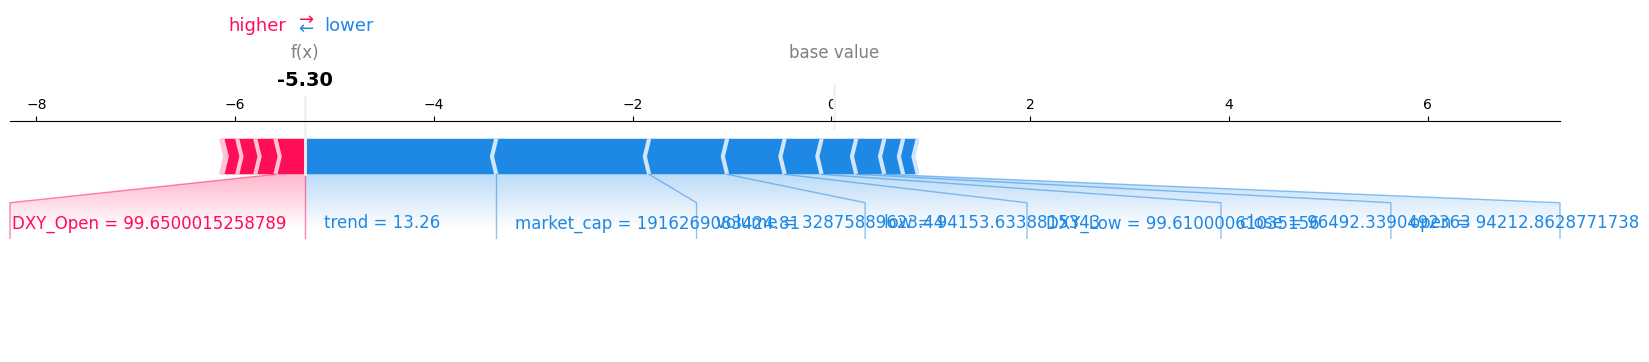

In [ ]:

print(f"\nForce Plot for {keywords} on {trade_date}:")
shap.force_plot(
    base_value,
    shap_values[sample_idx],
    X_test.iloc[sample_idx],
    matplotlib=True
)
plt.show()

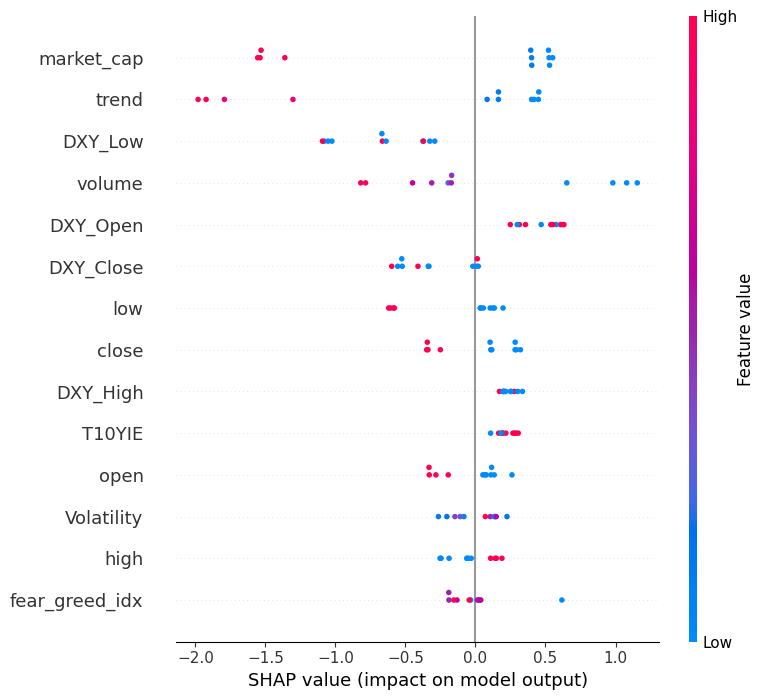

In [ ]:
shap.summary_plot(shap_values, X_test, show=True)

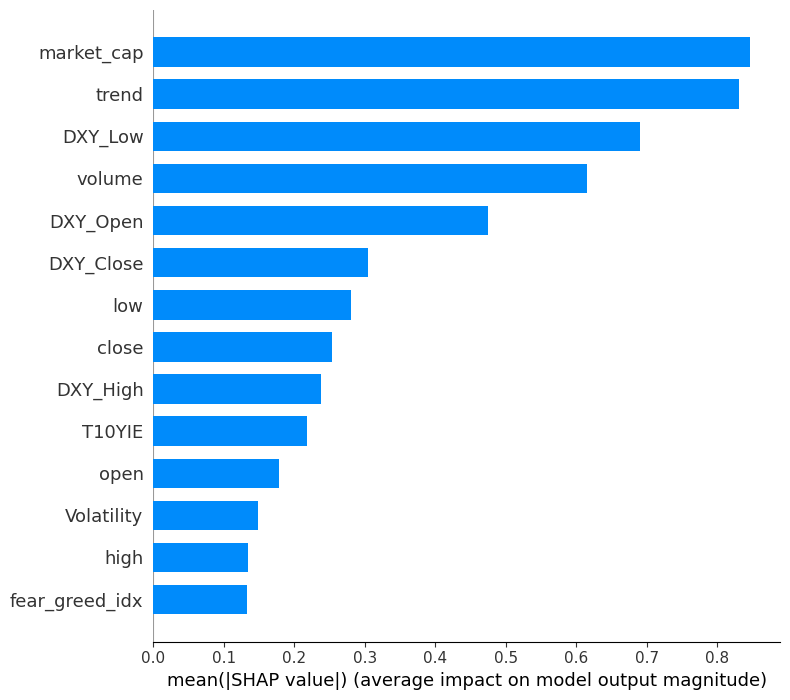

In [ ]:

shap.summary_plot(shap_values, X_test, plot_type="bar", show=True)

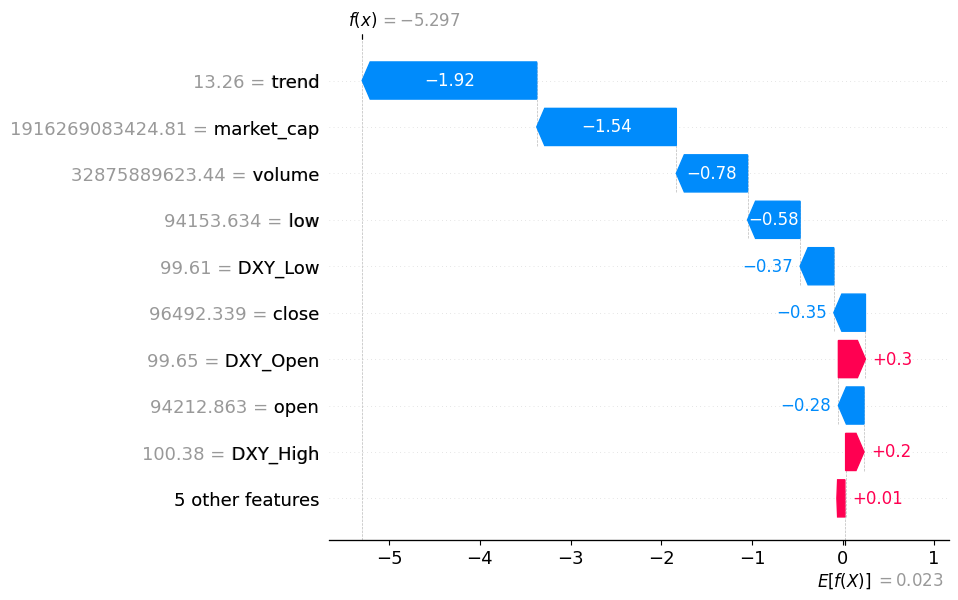

In [ ]:
shap_explanation = shap.Explanation(
    values=shap_values[sample_idx],
    base_values=base_value,
    data=X_test.iloc[sample_idx].values,
    feature_names=X_test.columns.tolist()
)
shap.waterfall_plot(shap_explanation, show=True)

In [ ]:
# ---------------------------------------------------------------
# STEP B: SIGNAL-BASED VECTORIZED BACKTESTING (XGBOOST)
# ---------------------------------------------------------------
import matplotlib.pyplot as plt

# 1. PREPARATION: Align Predictions with Returns
# We grab the date, symbol, and daily returns from our reconciled Test Set
results_df = df_test[['date', 'symbol', 'returns']].copy()
results_df['signal'] = y_pred_xgb_test  # Using our best performer

# --- CRITICAL ALIGNMENT ---
# Model makes a decision at 'Close' today for the price move 'Tomorrow'
# We group by symbol to ensure shifts don't cross between different coins
results_df['actual_next_day_ret'] = results_df.groupby('symbol')['returns'].shift(-1)
results_df['strategy_return'] = results_df['signal'] * results_df['actual_next_day_ret']

# 2. CUMULATIVE GAINS (Calculating the Equity Curve)
results_df['strategy_return'] = results_df['strategy_return'].fillna(0)

# Calculate growth of $1 for both Strategy and Benchmark
# Note: For multi-coin, we look at the aggregate average return across the test coins
portfolio_stats = results_df.groupby('date').agg({
    'strategy_return': 'mean',
    'returns': 'mean'
}).reset_index()

portfolio_stats['cum_strategy'] = (1 + portfolio_stats['strategy_return']).cumprod()
portfolio_stats['cum_benchmark'] = (1 + portfolio_stats['returns']).cumprod()

# 3. PERFORMANCE METRICS
n_buys = results_df['signal'].sum()
avg_ret_per_trade = results_df[results_df['signal'] == 1]['actual_next_day_ret'].mean()
total_gain_strat = (portfolio_stats['cum_strategy'].iloc[-1] - 1) * 100
total_gain_bh = (portfolio_stats['cum_benchmark'].iloc[-1] - 1) * 100

print("="*60)
print("BACKTEST RESULTS: XGBOOST STRATEGY (MAY 2025 RECONCILIATION)")
print("="*60)
print(f"Total Buy Signals Triggered: {int(n_buys)}")
print(f"Average Return per Trade:    {avg_ret_per_trade:.2%}")
print(f"Strategy Total Return:      {total_gain_strat:.2f}%")
print(f"Benchmark (Buy & Hold):     {total_gain_bh:.2f}%")
print("="*60)

# 4. PLOTTING THE EQUITY CURVE
plt.figure(figsize=(12, 6))
plt.plot(portfolio_stats['date'], portfolio_stats['cum_strategy'],
         label= 'XGBoost Model', color='green', lw=2.5)
plt.plot(portfolio_stats['date'], portfolio_stats['cum_benchmark'],
         label='Passive Benchmark (Buy & Hold)', color='gray', alpha=0.6, linestyle='--')

plt.title('Equity Curve: XGBoost vs. Passive Holding (Unseen Test Period)')
plt.xlabel('Date')
plt.ylabel('Growth of Initial $1 Investment')
plt.legend(loc='upper left')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import time
from pytrends.request import TrendReq

def fetch_trends_daily_long_multi_no_anchor(
    keywords,
    start="2020-01-01",
    end="2025-12-31",
    geo="",
    hl="en-US",
    chunk_days=200,
    overlap_days=30,
    sleep=1.0,
):
    pytrends = TrendReq(hl=hl, tz=0)
    start = pd.to_datetime(start)
    end = pd.to_datetime(end)

    step = chunk_days - overlap_days
    parts = []

    cur_start = start
    while cur_start <= end:
        cur_end = min(cur_start + pd.Timedelta(days=chunk_days - 1), end)
        timeframe = f"{cur_start:%Y-%m-%d} {cur_end:%Y-%m-%d}"

        pytrends.build_payload(
            kw_list=keywords,
            timeframe=timeframe,
            geo=geo
        )
        df = pytrends.interest_over_time()

        if df.empty:
            raise RuntimeError(f"No data returned for {timeframe}")

        df = df.drop(columns=["isPartial"], errors="ignore")
        parts.append(df)

        cur_start = cur_start + pd.Timedelta(days=step)
        time.sleep(sleep)

    stitched = pd.concat(parts, axis=0)

    stitched = stitched[~stitched.index.duplicated(keep="first")]
    stitched = stitched.sort_index()

    # scale 0-100
    max_all = stitched[keywords].to_numpy().max()
    if pd.notna(max_all) and max_all > 0:
        stitched[keywords] = (stitched[keywords] / max_all * 100).round(2)

    return stitched

keywords = ['bitcoin', 'ethereum', 'ripple', 'binance']

df_daily = fetch_trends_daily_long_multi_no_anchor(
    keywords=keywords,
    start="2020-01-01",
    end="2025-12-31",
    geo="",
    chunk_days=200,
    overlap_days=30,
    sleep=1.0
)

print(df_daily.head())
print(df_daily.tail())

            bitcoin  ethereum  ripple  binance
date                                          
2020-01-01     23.0       2.0     2.0      1.0
2020-01-02     26.0       2.0     2.0      1.0
2020-01-03     29.0       2.0     2.0      1.0
2020-01-04     26.0       2.0     2.0      1.0
2020-01-05     26.0       2.0     3.0      1.0
            bitcoin  ethereum  ripple  binance
date                                          
2025-12-27     30.0       4.0     3.0      5.0
2025-12-28     29.0       4.0     3.0      5.0
2025-12-29     32.0       5.0     3.0      5.0
2025-12-30     29.0       4.0     3.0      5.0
2025-12-31     28.0       4.0     3.0      5.0


In [ ]:
import pandas as pd
from pytrends.request import TrendReq

def fetch_trends_one_shot(
    keywords,
    start="2020-01-01",
    end="2025-12-31",
    geo="",
    hl="en-US"
):
    pytrends = TrendReq(hl=hl, tz=0)

    timeframe = f"{start} {end}"
    pytrends.build_payload(
        kw_list=keywords,
        timeframe=timeframe,
        geo=geo
    )

    df = pytrends.interest_over_time()

    if df.empty:
        raise RuntimeError(f"No data returned for {timeframe}")

    df = df.drop(columns=["isPartial"], errors="ignore")
    return df

In [ ]:
keywords = ['bitcoin', 'ethereum', 'ripple', 'binance']

df_daily = fetch_trends_one_shot(
    keywords=keywords,
    start="2020-01-01",
    end="2025-12-31",
    geo=""
)

print(df_daily.head())
print(df_daily.tail())

TooManyRequestsError: The request failed: Google returned a response with code 429